# Week 5 Day 6 — Daily Challenge
## Interactive Data Visualization with Matplotlib and Seaborn

**Objective:** Clean the US Superstore dataset; examine sales trends, geography, top products and discount/profit relationships; compare visualization tools and recommend business actions.

Run all cells in Jupyter. Interactive controls require an active notebook kernel.

## 1. Setup and data preparation
The notebook downloads the `.xls` file automatically, or reads a local copy in the same directory. Required packages: `pandas numpy matplotlib seaborn xlrd ipywidgets plotly requests`.

In [1]:
from pathlib import Path
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, Markdown
import plotly.express as px

sns.set_theme(style="whitegrid")
DATA_URL = "https://github.com/devtlv/Datasets-DA-Bootcamp-2-/raw/refs/heads/main/Week%205%20-%20Data%20Processing/W5D5%20-%20Mini-project%20-%20bis/US%20Superstore%20data.xls"
DATA_FILE = Path('US Superstore data.xls')
if DATA_FILE.exists():
    raw = DATA_FILE.read_bytes()
    print('Loaded local file:', DATA_FILE)
else:
    print('Downloading dataset...')
    response = requests.get(DATA_URL, timeout=60)
    response.raise_for_status()
    raw = response.content
    print('Downloaded', len(raw), 'bytes')

df_raw = pd.read_excel(io.BytesIO(raw), engine='xlrd')
print('Original shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())
display(df_raw.head())
print('Missing values:')
display(df_raw.isna().sum().to_frame('Missing'))
print('Exact duplicate rows:', df_raw.duplicated().sum())

Downloaded 3348992 bytes


C:\Users\Avi\AppData\Local\Temp\ipykernel_7260\2053771491.py:25: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df_raw = pd.read_excel(io.BytesIO(raw), engine='xlrd')


Original shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Missing values:


,Missing
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Exact duplicate rows: 0


### Cleaning decisions
- Remove exact duplicate records, but do **not** remove repeated order IDs because an order can have several product lines.
- Drop rows missing required analytical fields (dates, geography, product, sales, profit, discount) rather than invent financial values.
- Parse dates and numeric values; discard rows with invalid dates or financial values.
- Keep postal codes as identifiers, not numerical measures; missing postal codes are acceptable for this analysis.
- Profit margin uses aggregated profit divided by aggregated sales, not the average of row-level margins.

In [2]:
df = df_raw.drop_duplicates().copy()
required = ['Order Date', 'Country', 'State', 'Product Name', 'Category', 'Sales', 'Profit', 'Discount']
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {missing_columns}')
for c in ['Order Date', 'Ship Date']:
    if c in df:
        df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)
for c in ['Sales', 'Profit', 'Discount']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=required)
df = df[(df['Sales'] >= 0) & df['Discount'].between(0, 1)].copy()
df['Order Year'] = df['Order Date'].dt.year.astype(int)
df['Order Month'] = df['Order Date'].dt.to_period('M').dt.to_timestamp()
print('Cleaned shape:', df.shape)
print('Years:', sorted(df['Order Year'].unique().tolist()))
print('Countries:', df['Country'].value_counts().to_dict())
print('Total sales: ${:,.2f} | Total profit: ${:,.2f}'.format(df['Sales'].sum(), df['Profit'].sum()))
display(df[['Order Date','Country','State','Product Name','Sales','Profit','Discount']].head())

Cleaned shape: (9994, 23)
Years: [2014, 2015, 2016, 2017]
Countries: {'United States': 9994}
Total sales: $2,297,200.86 | Total profit: $286,397.02


,Order Date,Country,State,Product Name,Sales,Profit,Discount
0,2016-11-08,United States,Kentucky,Bush Somerset Collection Bookcase,261.9600,41.9136,0.00
1,2016-11-08,United States,Kentucky,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,219.5820,0.00
2,2016-06-12,United States,California,Self-Adhesive Address Labels for Typewriters b...,14.6200,6.8714,0.00
3,2015-10-11,United States,Florida,Bretford CR4500 Series Slim Rectangular Table,957.5775,-383.0310,0.45
4,2015-10-11,United States,Florida,Eldon Fold 'N Roll Cart System,22.3680,2.5164,0.20


## 2. Matplotlib — interactive sales trend
Select a product category and a year grouping. The chart updates inside Jupyter using `ipywidgets`.

In [3]:
category_options = ['All'] + sorted(df['Category'].dropna().unique().tolist())
category_selector = widgets.Dropdown(options=category_options, description='Category:')
period_selector = widgets.ToggleButtons(options=['Monthly', 'Yearly'], description='Period:')

def sales_trend(category, period):
    filtered = df if category == 'All' else df[df['Category'] == category]
    grouping = 'Order Month' if period == 'Monthly' else 'Order Year'
    trend = filtered.groupby(grouping, as_index=True)['Sales'].sum().sort_index()
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(trend.index, trend.values, marker='o', markersize=3, linewidth=2)
    ax.set_title(f'{period} Sales Trend — {category}')
    ax.set_xlabel('Order date')
    ax.set_ylabel('Total sales ($)')
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

widgets.interact(sales_trend, category=category_selector, period=period_selector);

interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…

## 3. Interactive geographic sales map
A world choropleth aggregates sales by **country**. If this dataset covers only the United States, a country map contains just one observation and cannot compare countries meaningfully. Therefore, the next chart also provides a more informative **interactive US state map**. Both maps use Plotly for pan/zoom/hover interactivity; Matplotlib is used for the required interactive time-series plot.

In [4]:
country_sales = df.groupby('Country', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
display(country_sales)
fig = px.choropleth(country_sales, locations='Country', locationmode='country names', color='Sales',
                    hover_name='Country', color_continuous_scale='Blues',
                    title='Interactive Map — Total Sales by Country')
fig.update_geos(showcoastlines=True, showland=True)
fig.show()
if country_sales['Country'].nunique() == 1:
    print('Only one country is present. State-level comparison is more informative.')

,Country,Sales
0,United States,2.297201e+06


Only one country is present. State-level comparison is more informative.


In [5]:
# Map US state names to postal abbreviations for Plotly's USA choropleth.
state_codes = dict(zip(
    ['Alabama','Alaska','Arizona','Arkansas','California','Colorado','Connecticut','Delaware','Florida','Georgia','Hawaii','Idaho','Illinois','Indiana','Iowa','Kansas','Kentucky','Louisiana','Maine','Maryland','Massachusetts','Michigan','Minnesota','Mississippi','Missouri','Montana','Nebraska','Nevada','New Hampshire','New Jersey','New Mexico','New York','North Carolina','North Dakota','Ohio','Oklahoma','Oregon','Pennsylvania','Rhode Island','South Carolina','South Dakota','Tennessee','Texas','Utah','Vermont','Virginia','Washington','West Virginia','Wisconsin','Wyoming','District of Columbia'],
    ['AL','AK','AZ','AR','CA','CO','CT','DE','FL','GA','HI','ID','IL','IN','IA','KS','KY','LA','ME','MD','MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ','NM','NY','NC','ND','OH','OK','OR','PA','RI','SC','SD','TN','TX','UT','VT','VA','WA','WV','WI','WY','DC']))
state_sales = df.groupby('State', as_index=False).agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
state_sales['State Code'] = state_sales['State'].map(state_codes)
if state_sales['State Code'].notna().any():
    fig = px.choropleth(state_sales.dropna(subset=['State Code']), locations='State Code', locationmode='USA-states',
                        color='Sales', scope='usa', hover_name='State', hover_data=['Profit'],
                        color_continuous_scale='Blues', title='Interactive US Map — Sales by State')
    fig.show()
else:
    print('State codes not recognized; displaying a ranked state table instead.')
display(state_sales.sort_values('Sales', ascending=False).head(10))

,State,Sales,Profit,State Code
3,California,457687.6315,76381.3871,CA
30,New York,310876.2710,74038.5486,NY
41,Texas,170188.0458,-25729.3563,TX
45,Washington,138641.2700,33402.6517,WA
36,Pennsylvania,116511.9140,-15559.9603,PA
8,Florida,89473.7080,-3399.3017,FL
11,Illinois,80166.1010,-12607.8870,IL
33,Ohio,78258.1360,-16971.3766,OH
20,Michigan,76269.6140,24463.1876,MI
44,Virginia,70636.7200,18597.9504,VA


## 4. Seaborn — top 10 products by total sales
Product names are aggregated before ranking; this avoids ranking individual order lines as if they were products.

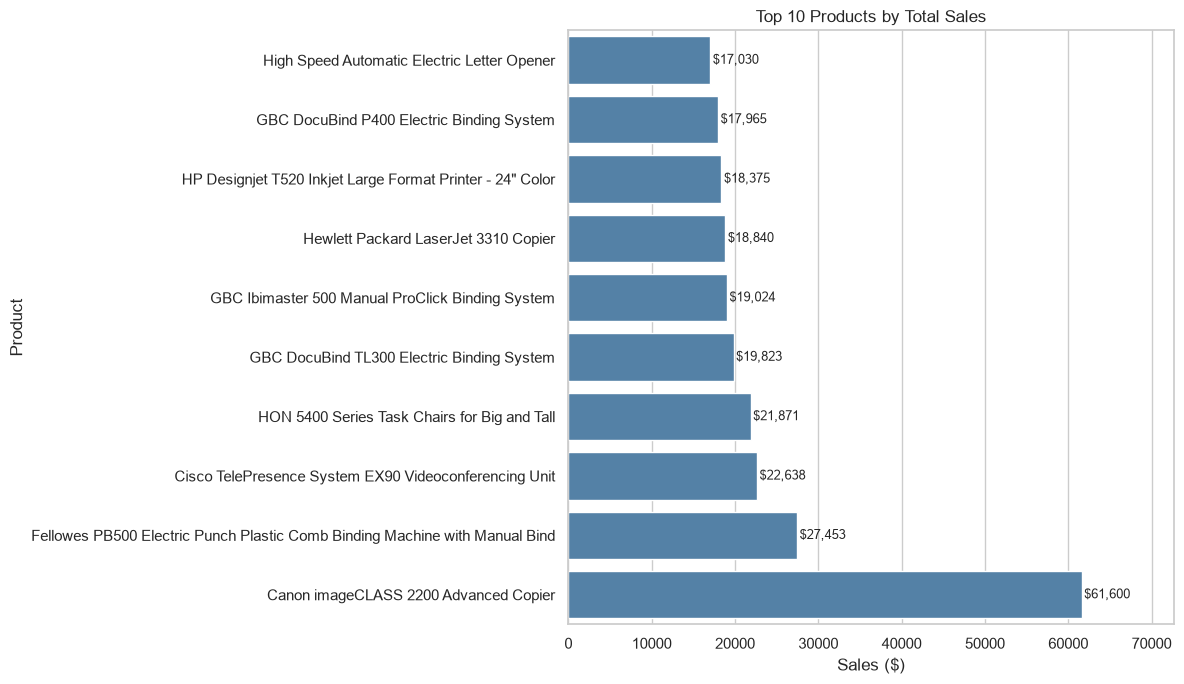

,Product Name,Sales
404,Canon imageCLASS 2200 Advanced Copier,61599.824
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480
786,HON 5400 Series Task Chairs for Big and Tall,21870.576
686,GBC DocuBind TL300 Electric Binding System,19823.479
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.500
805,Hewlett Packard LaserJet 3310 Copier,18839.686
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
683,GBC DocuBind P400 Electric Binding System,17965.068
813,High Speed Automatic Electric Letter Opener,17030.312


In [6]:
top_products = df.groupby('Product Name', as_index=False)['Sales'].sum().nlargest(10, 'Sales').sort_values('Sales')
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=top_products, x='Sales', y='Product Name', color='steelblue', ax=ax)
for i, value in enumerate(top_products['Sales']):
    ax.text(value + top_products['Sales'].max()*0.005, i, f'${value:,.0f}', va='center', fontsize=9)
ax.set_xlim(0, top_products['Sales'].max()*1.18)
ax.set_title('Top 10 Products by Total Sales')
ax.set_xlabel('Sales ($)')
ax.set_ylabel('Product')
plt.tight_layout()
plt.show()
display(top_products.sort_values('Sales', ascending=False))

## 5. Seaborn — discount versus profit
Points represent individual order lines, colored by category. A fitted regression line summarizes association, **not causation**. High discounts may be associated with losses, but the plot alone does not prove discounts caused them.

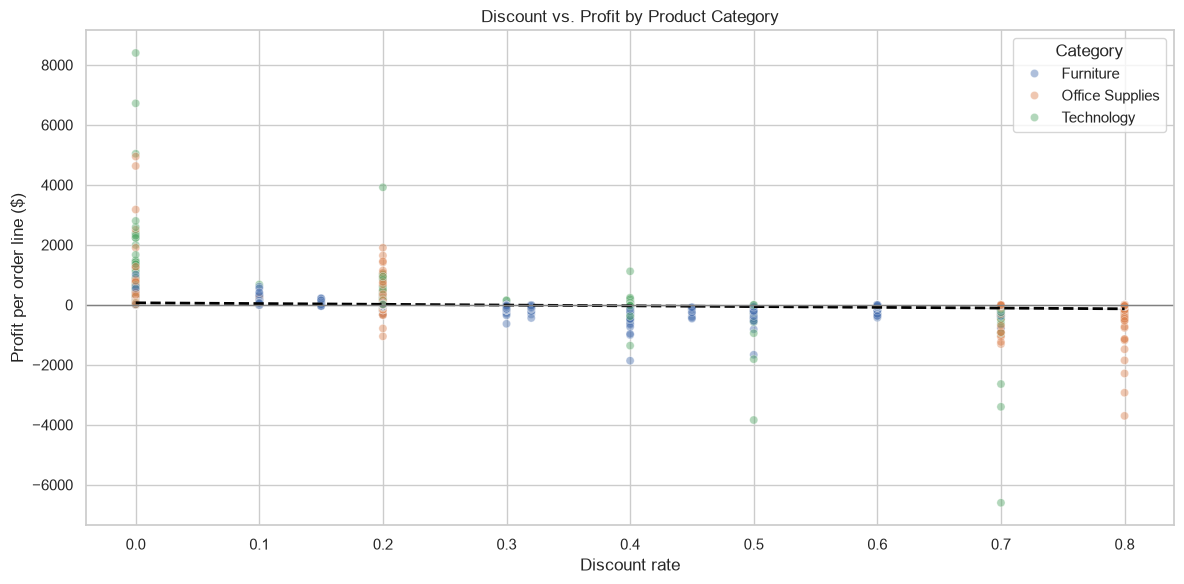

,Discount Group,Orders,Average_Profit,Total_Profit,Loss_Rate
0,0%,4798,66.900292,320987.6032,0.000000
1,>0–10%,94,96.055074,9029.1770,4.255319
2,>10–20%,3709,24.738824,91756.2975,13.992990
3,>20–40%,460,-77.864055,-35817.4655,90.217391
4,>40%,933,-106.708028,-99558.5905,100.000000


In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.45, s=35, ax=ax)
sns.regplot(data=df, x='Discount', y='Profit', scatter=False, color='black',
            line_kws={'linestyle':'--','linewidth':2}, ax=ax)
ax.axhline(0, color='gray', linewidth=1)
ax.set_title('Discount vs. Profit by Product Category')
ax.set_xlabel('Discount rate')
ax.set_ylabel('Profit per order line ($)')
plt.tight_layout()
plt.show()

df['Discount Group'] = pd.cut(df['Discount'], bins=[-0.001, 0, .1, .2, .4, 1],
                              labels=['0%', '>0–10%', '>10–20%', '>20–40%', '>40%'])
discount_summary = df.groupby('Discount Group', observed=True).agg(
    Orders=('Profit','size'), Average_Profit=('Profit','mean'), Total_Profit=('Profit','sum'),
    Loss_Rate=('Profit', lambda s: (s < 0).mean()*100)).reset_index()
display(discount_summary)

## 6. Comparative analysis: Matplotlib vs. Seaborn

| Aspect | Matplotlib | Seaborn |
|---|---|---|
| Control | Fine control of ticks, labels, layout and annotations | Higher-level statistical defaults |
| Interactive widgets | Works with `ipywidgets` callbacks | Can also work with widgets, via Matplotlib |
| Statistical plots | More manual code for regression and categories | Convenient `regplot` and `scatterplot` |
| Visual presentation | Fully customizable | Attractive consistent defaults |

**Observation:** Matplotlib suits the interactive time-series chart because precise formatting and widget integration are straightforward. Seaborn makes the product bar chart and discount-profit relationship concise and readable. **Plotly** was used for the interactive geographic map because it provides built-in geographic hover and zoom; a plain Matplotlib figure would require additional mapping and interaction code.

**Limitations:** The dataset is historical; geographic sales totals do not measure market potential without population or customer-base denominators. A relationship between discount and profit is not proof of causation.

## 7. Automatically generated insights and recommendations
Run this cell after the charts to calculate findings from the actual dataset.

In [8]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
margin = 100 * total_profit / total_sales if total_sales else float('nan')
leading_state = state_sales.sort_values('Sales', ascending=False).iloc[0]
leading_product = top_products.sort_values('Sales', ascending=False).iloc[0]
yearly_sales = df.groupby('Order Year')['Sales'].sum().sort_index()
loss_high = (df.loc[df['Discount'] > .2, 'Profit'] < 0).mean() * 100
loss_low = (df.loc[df['Discount'] <= .2, 'Profit'] < 0).mean() * 100
high_n = int((df['Discount'] > .2).sum())
low_n = int((df['Discount'] <= .2).sum())
print('EXECUTIVE SUMMARY')
print(f'1. Revenue ${total_sales:,.2f}; profit ${total_profit:,.2f}; overall margin {margin:.2f}%.')
print(f'2. Leading state by sales: {leading_state["State"]} (${leading_state["Sales"]:,.2f}).')
print(f'3. Leading product by sales: {leading_product["Product Name"]} (${leading_product["Sales"]:,.2f}).')
print(f'4. Loss rate: discounts >20% = {loss_high:.1f}% (n={high_n}); discounts <=20% = {loss_low:.1f}% (n={low_n}).')
print(f'5. First/last year sales: {yearly_sales.index[0]} = ${yearly_sales.iloc[0]:,.2f}; {yearly_sales.index[-1]} = ${yearly_sales.iloc[-1]:,.2f}.')
print()
print('RECOMMENDATIONS')
print('- Review profitable high-sales states and products for targeted marketing, not sales alone.')
print('- Audit high-discount order lines by category and test changes before setting a blanket cap.')
print('- Compare state profit margins and customer demand before reallocating budgets.')
print('- Use interactive charts for exploration and Seaborn static figures for reporting.')

EXECUTIVE SUMMARY
1. Revenue $2,297,200.86; profit $286,397.02; overall margin 12.47%.
2. Leading state by sales: California ($457,687.63).
3. Leading product by sales: Canon imageCLASS 2200 Advanced Copier ($61,599.82).
4. Loss rate: discounts >20% = 96.8% (n=1393); discounts <=20% = 6.1% (n=8601).
5. First/last year sales: 2014 = $484,247.50; 2017 = $733,215.26.

RECOMMENDATIONS
- Review profitable high-sales states and products for targeted marketing, not sales alone.
- Audit high-discount order lines by category and test changes before setting a blanket cap.
- Compare state profit margins and customer demand before reallocating budgets.
- Use interactive charts for exploration and Seaborn static figures for reporting.


## 8. Submission notes
Save this notebook **after executing all cells**, so GitHub can display outputs. Include `README.md` with findings and a link to this notebook. The interactive controls require Jupyter and will not run on GitHub's static notebook preview.